# County-Level Presidential Participation: Initial Report and EDA
**Author:** Mikaela Beck  
**Assignment:** Required Capstone Assignment 20.1  
**Data retrieved:** October 28, 2026

## Executive brief and research scope
The submitted research question is: **Which demographic, political, and campaign-context factors are most predictive of voter turnout in U.S. elections?**

This initial report studies county-level **2024 presidential participation**, using demographic estimates and 2020 political context. The outcome is **100 × 2024 presidential votes / ACS estimated residents age 18 or older**. It is a voting-age-population participation proxy, not official registered-voter turnout or voting-eligible-population turnout. It includes noncitizens and other ineligible adults in its denominator, excludes ballots without a presidential vote in its numerator, and uses a five-year population estimate rather than an election-day count.

This is a retrospective county-level analysis. ACS 2020–2024 estimates were released after the election, so results must not be described as a deployable pre-election forecast. Counties describe aggregate patterns; the model does not identify individual voters or estimate the causal effect of outreach.

### Changes from the Module 16 proposal
The county-level question and proposed source families are retained. This first analysis uses one election cycle, with 2020 returns supplying prior political context. No verified historical turnout rate is available in the assembled data, so prior turnout is deferred. FEC spending, an urban/rural classification, and clustering are also deferred. A defensible county allocation of campaign spending has not been established. This report compares a constant baseline, Ridge regression, and a random forest; it does not claim to answer the campaign-spending part of the broader question yet.

In [1]:
from pathlib import Path
import gzip
import json
import platform
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / 'data/raw').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/raw').exists(), 'Run from the project root or notebooks directory.'
RAW = ROOT / 'data/raw'
PROCESSED = ROOT / 'data/processed'
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
SEED = 42
pd.set_option('display.max_columns', 16)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 160})

def save_figure(filename):
    plt.tight_layout()
    plt.savefig(FIGURES / filename, bbox_inches='tight')
    plt.show()
    plt.close()

sources = json.loads((RAW / 'sources.json').read_text())
display(Markdown('**Reproducibility:** raw snapshots and SHA-256 checksums are in `data/raw/sources.json`. All processing and modeling below use those local snapshots.'))

**Reproducibility:** raw snapshots and SHA-256 checksums are in `data/raw/sources.json`. All processing and modeling below use those local snapshots.

## 1. Sources and geographic coverage
Election returns originate with [MIT Election Data and Science Lab, Harvard Dataverse V20](https://doi.org/10.7910/DVN/VOQCHQ). This notebook uses the [Election Data mirror](https://electiondata.dev/datasets/county-president/) because Harvard's direct file endpoint required a guestbook response. The mirror normalizes vote modes and reporting-unit identifiers. Its provenance/version are preserved; equality to a directly downloaded Harvard datafile was not independently checked.

Demographics originate with the U.S. Census Bureau's ACS and were retrieved from [Census Reporter](https://censusreporter.org/about/), release `acs2024_5yr` (2020–2024). Both estimates and margins of error are preserved in the raw JSON. Tables: B01001 age, B15003 education, B17001 poverty, B19013 household income, and B03002 race/ethnicity. This descriptive analysis uses point estimates; ACS sampling uncertainty is not propagated into the model.

The join uses five-digit county FIPS, never county names. Alaska election districts do not align with borough/census-area geography. Connecticut's old election counties do not align with the new ACS planning regions. Unmatched units remain in an audit file and are excluded from modeling without invented crosswalks. Puerto Rico has ACS data but no general-election presidential county votes in these returns.

In [2]:
election_2024 = pd.read_csv(RAW / 'elections_2024.csv', dtype={'county_fips': 'string'})
election_2020 = pd.read_csv(RAW / 'elections_2020.csv', dtype={'county_fips': 'string'})
with gzip.open(RAW / 'acs2024_counties.json.gz', 'rt') as handle:
    acs_payload = json.load(handle)
assert acs_payload['release']['id'] == 'acs2024_5yr'
assert set(election_2024['year']) == {2024}
assert set(election_2020['year']) == {2020}
audit = {'raw_election_2024_rows': len(election_2024), 'raw_election_2020_rows': len(election_2020), 'acs_counties': len(acs_payload['data'])}
display(pd.DataFrame([
    {'source': '2024 candidate rows', 'rows': len(election_2024)},
    {'source': '2020 candidate rows', 'rows': len(election_2020)},
    {'source': 'ACS county records', 'rows': len(acs_payload['data'])},
]))
display(pd.DataFrame({table: {'title': metadata['title'], 'universe': metadata['universe']} for table, metadata in acs_payload['tables'].items()}).T)

,source,rows
0,2024 candidate rows,12514
1,2020 candidate rows,13656
2,ACS county records,3222


,title,universe
B01001,Sex by Age,Total population
B03002,Hispanic or Latino Origin by Race,Total population
B15003,Educational Attainment for the Population 25 Y...,Population 25 years and over
B17001,Poverty Status in the Past 12 Months by Sex by...,Population for whom poverty status is determined
B19013,Median Household Income in the Past 12 Months ...,Households


## 2. Election cleaning: prevent repeated-total double counting
Each candidate row repeats a county's `totalvotes`. Summing that field would multiply turnout by the number of candidates. First confirm one unique total per reporting unit, then retain it once. Exact duplicate rows are counted and removed; conflicting candidate keys cause an assertion failure. The sum of candidate votes is a separate reconciliation check. Differences are flagged and retained because the source explicitly supplies the county total; they are not silently overwritten. Sensitivity to flagged counties is assessed later.

In [3]:
def summarize_election(frame, label):
    audit[label + '_exact_duplicate_rows'] = int(frame.duplicated().sum())
    frame = frame.drop_duplicates().copy()
    candidate_keys = ['year', 'state_po', 'unit_id', 'candidate', 'party']
    assert not frame.duplicated(candidate_keys).any(), 'Conflicting candidate keys require inspection.'
    assert frame.groupby('unit_id')['totalvotes'].nunique().max() == 1
    grouped = frame.groupby('unit_id', dropna=False)
    units = grouped.agg(county_fips=('county_fips', 'first'), county_name=('county_name', 'first'), state=('state_po', 'first'), total_votes=('totalvotes', 'first'))
    units['candidate_vote_sum'] = grouped['candidatevotes'].sum(min_count=1)
    units['candidate_total_gap'] = units['candidate_vote_sum'] - units['total_votes']
    units['candidate_gap_pct'] = 100 * units['candidate_total_gap'] / units['total_votes']
    units['total_reconciliation_flag'] = units['candidate_total_gap'].ne(0)
    valid_fips = units['county_fips'].str.fullmatch(r'\d{5}', na=False)
    audit[label + '_reporting_units'] = len(units)
    audit[label + '_units_without_county_fips'] = int((~valid_fips).sum())
    units.loc[~valid_fips].to_csv(REPORTS / (label + '_noncounty_units.csv'))
    units.loc[units['total_reconciliation_flag']].to_csv(REPORTS / (label + '_vote_reconciliation.csv'))
    units = units.loc[valid_fips].reset_index()
    assert not units['county_fips'].duplicated().any()
    audit[label + '_valid_county_units'] = len(units)
    audit[label + '_reconciliation_flags'] = int(units['total_reconciliation_flag'].sum())
    return units

counties_2024 = summarize_election(election_2024, 'election_2024')
counties_2020 = summarize_election(election_2020, 'election_2020')
prior_party_votes = election_2020.dropna(subset=['county_fips']).groupby(['county_fips', 'party'])['candidatevotes'].sum(min_count=1).unstack()
two_party_votes = prior_party_votes['DEMOCRAT'] + prior_party_votes['REPUBLICAN']
prior_context = pd.DataFrame({
    'prior_dem_share_pct': 100 * prior_party_votes['DEMOCRAT'] / two_party_votes,
    'prior_competitiveness': 100 * (1 - (prior_party_votes['DEMOCRAT'] - prior_party_votes['REPUBLICAN']).abs() / two_party_votes),
}).reset_index()
display(pd.Series(audit, name='count').to_frame())
display(counties_2024.loc[counties_2024['total_reconciliation_flag'], ['state', 'county_name', 'candidate_vote_sum', 'total_votes', 'candidate_gap_pct']].sort_values('candidate_gap_pct').head(8))

,count
raw_election_2024_rows,12514
raw_election_2020_rows,13656
acs_counties,3222
election_2024_exact_duplicate_rows,0
election_2024_reporting_units,3154
election_2024_units_without_county_fips,42
election_2024_valid_county_units,3112
election_2024_reconciliation_flags,127
election_2020_exact_duplicate_rows,0
election_2020_reporting_units,3155


,state,county_name,candidate_vote_sum,total_votes,candidate_gap_pct
67,AZ,APACHE,32101.0,32685,-1.786752
795,IA,GREENE,4881.0,4968,-1.751208
778,IA,CLARKE,4479.0,4552,-1.603691
79,AZ,SANTA CRUZ,19167.0,19428,-1.343422
831,IA,PAGE,7322.0,7419,-1.307454
809,IA,JEFFERSON,8346.0,8454,-1.277502
761,IA,ALLAMAKEE,7318.0,7410,-1.241565
851,IA,WAYNE,3124.0,3162,-1.201771


## 3. Demographic feature engineering and turnout proxy
Age 18+ equals B01001 total population minus male/female under-18 bins. Bachelor-or-higher percentage uses B15003 categories 22–25 divided by population age 25+. Poverty percentage uses B17001 population below poverty divided by its defined universe. Race/ethnicity shares use B03002: non-Hispanic White alone, non-Hispanic Black alone, and Hispanic of any race, each divided by total population. These are ecological descriptors, not individual behaviors; the three shares do not exhaust all categories. Income is in 2024 inflation-adjusted dollars.

Prior competitiveness is `100 × (1 − |D − R|/(D + R))` using 2020 presidential candidate votes. A value of 100 means a tied two-party vote; 0 means one party received all two-party votes. The log of population captures county size. FIPS is an identifier and state is a validation group; neither is a numeric predictor.

Census negative sentinel values become missing. Missing predictor values are imputed inside each training fold. Missing or nonpositive target denominators and turnout proxies outside 0–100 are excluded and logged, never clipped into range. Extreme but valid observations are retained and examined with IQR flags and robust-error metrics.

In [4]:
acs_rows = []
for geoid, tables in acs_payload['data'].items():
    record = {'county_fips': geoid[-5:], 'acs_county_name': acs_payload['geography'][geoid]['name']}
    for table_id, table_data in tables.items():
        for variable, estimate in table_data['estimate'].items():
            record[variable] = estimate
    acs_rows.append(record)
acs = pd.DataFrame(acs_rows)
assert not acs['county_fips'].duplicated().any()
numeric_columns = [column for column in acs if column.startswith('B')]
acs[numeric_columns] = acs[numeric_columns].apply(pd.to_numeric, errors='coerce')
audit['acs_negative_sentinel_cells'] = int((acs[numeric_columns] < 0).sum().sum())
acs[numeric_columns] = acs[numeric_columns].mask(acs[numeric_columns] < 0)

def age_sum(frame, bins):
    return frame[[f'B01001{number:03d}' for number in bins]].sum(axis=1, min_count=len(bins))

acs['population'] = acs['B01001001']
acs['adult_population'] = acs['population'] - age_sum(acs, [3, 4, 5, 6, 27, 28, 29, 30])
acs['pct_age_18_29'] = 100 * age_sum(acs, list(range(7, 12)) + list(range(31, 36))) / acs['population']
acs['pct_age_65_plus'] = 100 * age_sum(acs, list(range(20, 26)) + list(range(44, 50))) / acs['population']
acs['pct_bachelors_plus'] = 100 * acs[[f'B15003{number:03d}' for number in range(22, 26)]].sum(axis=1, min_count=4) / acs['B15003001']
acs['pct_poverty'] = 100 * acs['B17001002'] / acs['B17001001']
acs['median_household_income'] = acs['B19013001']
acs['pct_nonhispanic_white'] = 100 * acs['B03002003'] / acs['B03002001']
acs['pct_nonhispanic_black'] = 100 * acs['B03002004'] / acs['B03002001']
acs['pct_hispanic'] = 100 * acs['B03002012'] / acs['B03002001']
acs['log_population'] = np.log10(acs['population'].where(acs['population'] > 0))

demographic_columns = ['population', 'adult_population', 'pct_age_18_29', 'pct_age_65_plus', 'pct_bachelors_plus', 'pct_poverty', 'median_household_income', 'pct_nonhispanic_white', 'pct_nonhispanic_black', 'pct_hispanic', 'log_population']
merged = counties_2024.merge(acs[['county_fips', 'acs_county_name'] + demographic_columns], on='county_fips', how='left', validate='one_to_one', indicator=True)
unmatched = merged.loc[merged['_merge'] != 'both', ['county_fips', 'county_name', 'state']].copy()
unmatched.to_csv(REPORTS / 'election_counties_without_acs.csv', index=False)
audit['county_units_unmatched_to_acs'] = len(unmatched)
audit['acs_counties_without_2024_election_match'] = int((~acs['county_fips'].isin(counties_2024['county_fips'])).sum())
merged = merged.drop(columns='_merge').merge(prior_context, on='county_fips', how='left', validate='one_to_one')
merged['participation_pct'] = 100 * merged['total_votes'] / merged['adult_population']
merged['exclusion_reason'] = ''
merged.loc[merged['adult_population'].isna(), 'exclusion_reason'] = 'No ACS county match or missing adult population'
merged.loc[merged['adult_population'].le(0), 'exclusion_reason'] = 'Nonpositive adult population'
merged.loc[merged['participation_pct'].notna() & ~merged['participation_pct'].between(0, 100), 'exclusion_reason'] = 'Participation proxy outside 0-100'
excluded = merged.loc[merged['exclusion_reason'].ne('')].copy()
excluded.to_csv(REPORTS / 'excluded_counties.csv', index=False)
analysis = merged.loc[merged['exclusion_reason'].eq('')].drop(columns='exclusion_reason').copy()
analysis.replace([np.inf, -np.inf], np.nan, inplace=True)
FEATURES = ['log_population', 'pct_age_18_29', 'pct_age_65_plus', 'median_household_income', 'pct_bachelors_plus', 'pct_poverty', 'pct_nonhispanic_white', 'pct_nonhispanic_black', 'pct_hispanic', 'prior_dem_share_pct', 'prior_competitiveness']
assert analysis['county_fips'].is_unique
assert analysis['participation_pct'].between(0, 100).all()
assert analysis[FEATURES].notna().any().all()
for feature in [column for column in FEATURES if column.startswith('pct_') or column.startswith('prior_')]:
    assert analysis[feature].dropna().between(0, 100).all(), feature
analysis.to_csv(PROCESSED / 'county_analysis.csv', index=False)
audit.update({'excluded_county_rows': len(excluded), 'analysis_counties': len(analysis), 'analysis_states_and_dc': analysis['state'].nunique(), 'analysis_presidential_votes': int(analysis['total_votes'].sum())})
missingness = analysis[FEATURES].isna().sum().rename('missing_count').to_frame()
missingness['missing_pct'] = 100 * missingness['missing_count'] / len(analysis)
missingness.to_csv(REPORTS / 'predictor_missingness.csv')
display(pd.Series(audit, name='count').to_frame())
display(excluded[['state', 'county_name', 'participation_pct', 'exclusion_reason']])
display(Markdown('Five matched counties have ratios above 100%: Mineral (CO), Edwards, Kenedy, Loving, and McMullen (TX). They are excluded from the bounded-outcome analysis and retained in the audit. A ratio above 100% can reflect incompatibility or uncertainty in the population estimate and vote numerator; it is not evidence of improper voting. Excluding these observations also limits conclusions about small counties.'))
display(missingness.T)

/var/folders/tl/x6vvbs2d37x0tzpnb11s7l1r0000gn/T/ipykernel_12641/774260705.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  acs['population'] = acs['B01001001']
/var/folders/tl/x6vvbs2d37x0tzpnb11s7l1r0000gn/T/ipykernel_12641/774260705.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  acs['adult_population'] = acs['population'] - age_sum(acs, [3, 4, 5, 6, 27, 28, 29, 30])
/var/folders/tl/x6vvbs2d37x0tzpnb11s7l1r0000gn/T/ipykernel_12641/774260705.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually t

,count
raw_election_2024_rows,12514
raw_election_2020_rows,13656
acs_counties,3222
election_2024_exact_duplicate_rows,0
election_2024_reporting_units,3154
election_2024_units_without_county_fips,42
election_2024_valid_county_units,3112
election_2024_reconciliation_flags,127
election_2020_exact_duplicate_rows,0
election_2020_reporting_units,3155


,state,county_name,participation_pct,exclusion_reason
255,CO,MINERAL,117.107309,Participation proxy outside 0-100
279,CT,FAIRFIELD,NaN,No ACS county match or missing adult population
280,CT,HARTFORD,NaN,No ACS county match or missing adult population
281,CT,LITCHFIELD,NaN,No ACS county match or missing adult population
282,CT,MIDDLESEX,NaN,No ACS county match or missing adult population
283,CT,NEW HAVEN,NaN,No ACS county match or missing adult population
284,CT,NEW LONDON,NaN,No ACS county match or missing adult population
285,CT,TOLLAND,NaN,No ACS county match or missing adult population
286,CT,WINDHAM,NaN,No ACS county match or missing adult population
2561,TX,EDWARDS,101.106640,Participation proxy outside 0-100


Five matched counties have ratios above 100%: Mineral (CO), Edwards, Kenedy, Loving, and McMullen (TX). They are excluded from the bounded-outcome analysis and retained in the audit. A ratio above 100% can reflect incompatibility or uncertainty in the population estimate and vote numerator; it is not evidence of improper voting. Excluding these observations also limits conclusions about small counties.

,log_population,pct_age_18_29,pct_age_65_plus,median_household_income,pct_bachelors_plus,pct_poverty,pct_nonhispanic_white,pct_nonhispanic_black,pct_hispanic,prior_dem_share_pct,prior_competitiveness
missing_count,0.0,0.0,0.0,1.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
missing_pct,0.0,0.0,0.0,0.032268,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. EDA: distribution, missingness, outliers, and relationships
The unit of analysis is one county/county equivalent, so county averages are unweighted. The aggregate ratio of total votes to total adult population is reported separately; neither is an official national turnout statistic. An IQR rule describes unusual values without asserting errors or removing valid counties. Population size and ACS sampling uncertainty make very small counties especially important to inspect.

,county participation (%)
count,3099.00
mean,62.50
std,9.97
min,22.36
25%,56.08
50%,62.78
75%,69.64
max,97.32


**County mean:** 62.50%; **median:** 62.78%; **aggregate ratio within the analytical sample:** 59.31%. The IQR rule flags 30 counties, retained for analysis.

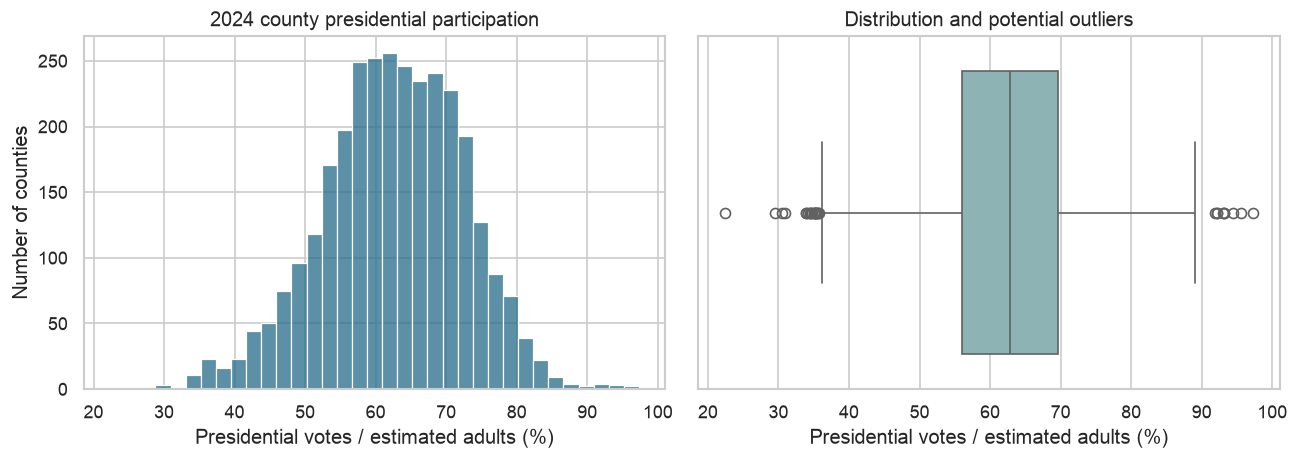

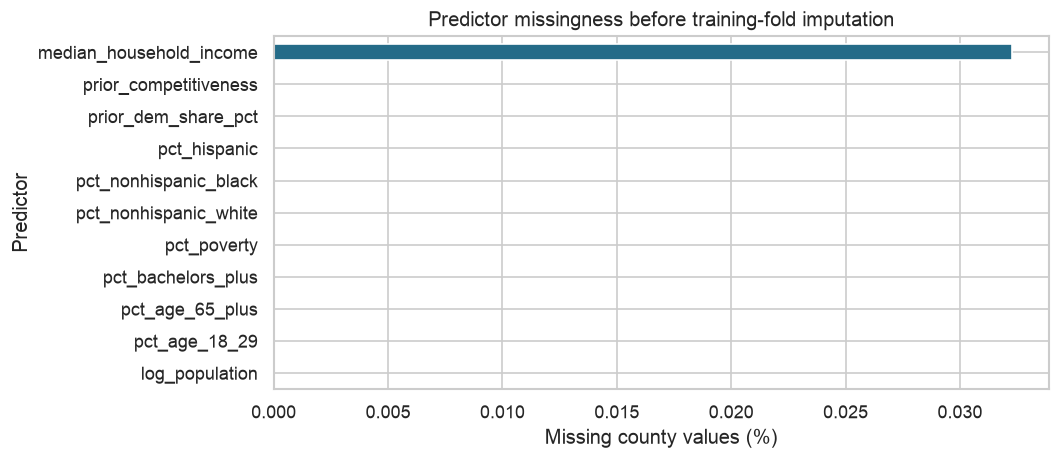

In [5]:
target = analysis['participation_pct']
first_quartile, third_quartile = target.quantile([0.25, 0.75])
iqr = third_quartile - first_quartile
analysis['target_iqr_outlier'] = ~target.between(first_quartile - 1.5 * iqr, third_quartile + 1.5 * iqr)
analysis.loc[analysis['target_iqr_outlier'], ['county_fips', 'state', 'county_name', 'total_votes', 'adult_population', 'participation_pct']].to_csv(REPORTS / 'target_iqr_outliers.csv', index=False)
distribution = target.describe().to_dict()
weighted_participation = 100 * analysis['total_votes'].sum() / analysis['adult_population'].sum()
display(target.describe().rename('county participation (%)').to_frame().round(2))
display(Markdown(f"**County mean:** {target.mean():.2f}%; **median:** {target.median():.2f}%; **aggregate ratio within the analytical sample:** {weighted_participation:.2f}%. The IQR rule flags {int(analysis['target_iqr_outlier'].sum())} counties, retained for analysis."))
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(target, bins=35, ax=axes[0], color='#246b88')
axes[0].set(title='2024 county presidential participation', xlabel='Presidential votes / estimated adults (%)', ylabel='Number of counties')
sns.boxplot(x=target, ax=axes[1], color='#87b9bb')
axes[1].set(title='Distribution and potential outliers', xlabel='Presidential votes / estimated adults (%)')
save_figure('01_participation_distribution.png')
figure, axis = plt.subplots(figsize=(9, 4))
missingness['missing_pct'].sort_values().plot.barh(ax=axis, color='#246b88')
axis.set(title='Predictor missingness before training-fold imputation', xlabel='Missing county values (%)', ylabel='Predictor')
save_figure('02_missingness.png')

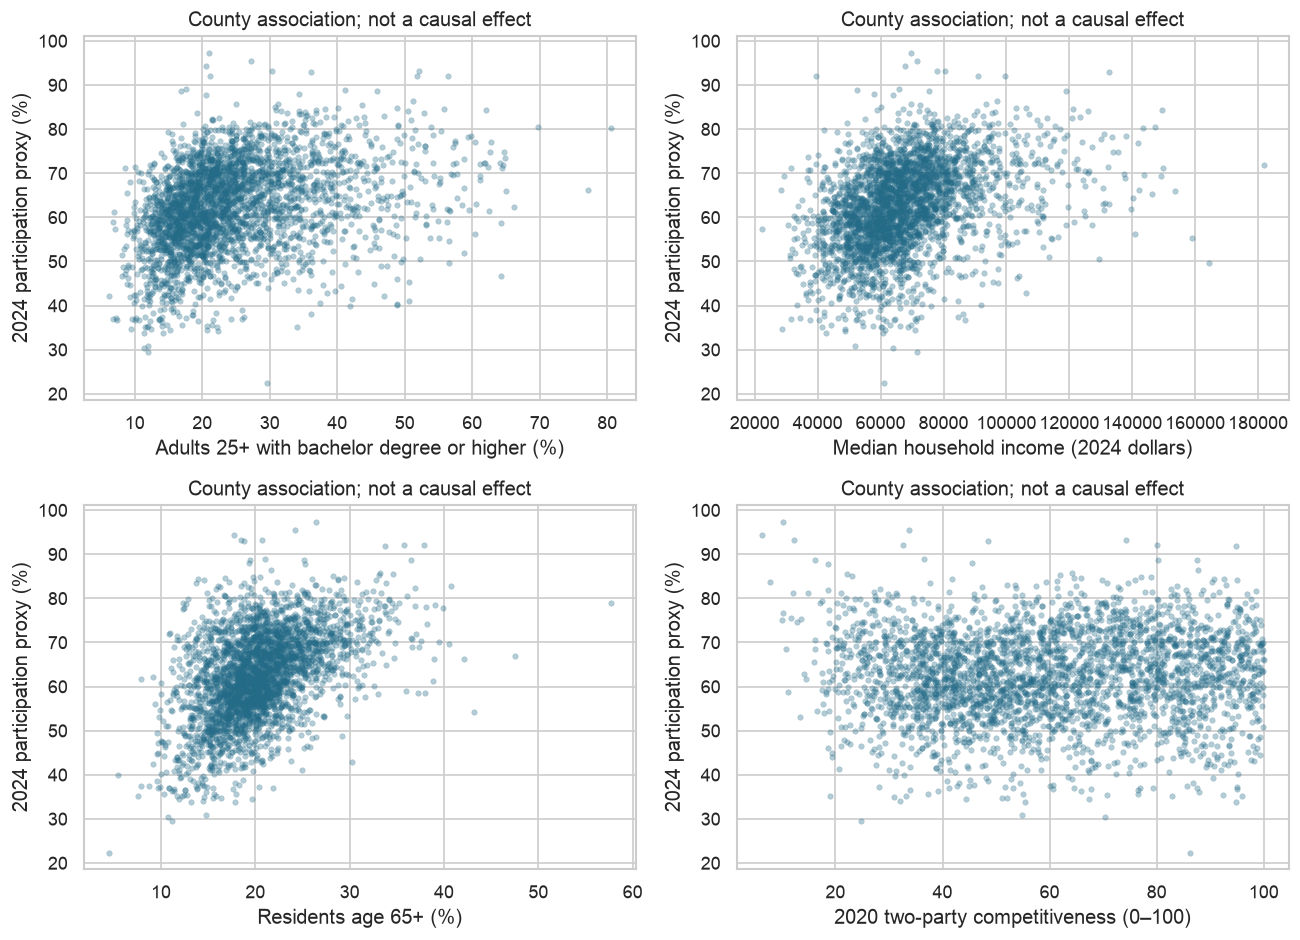

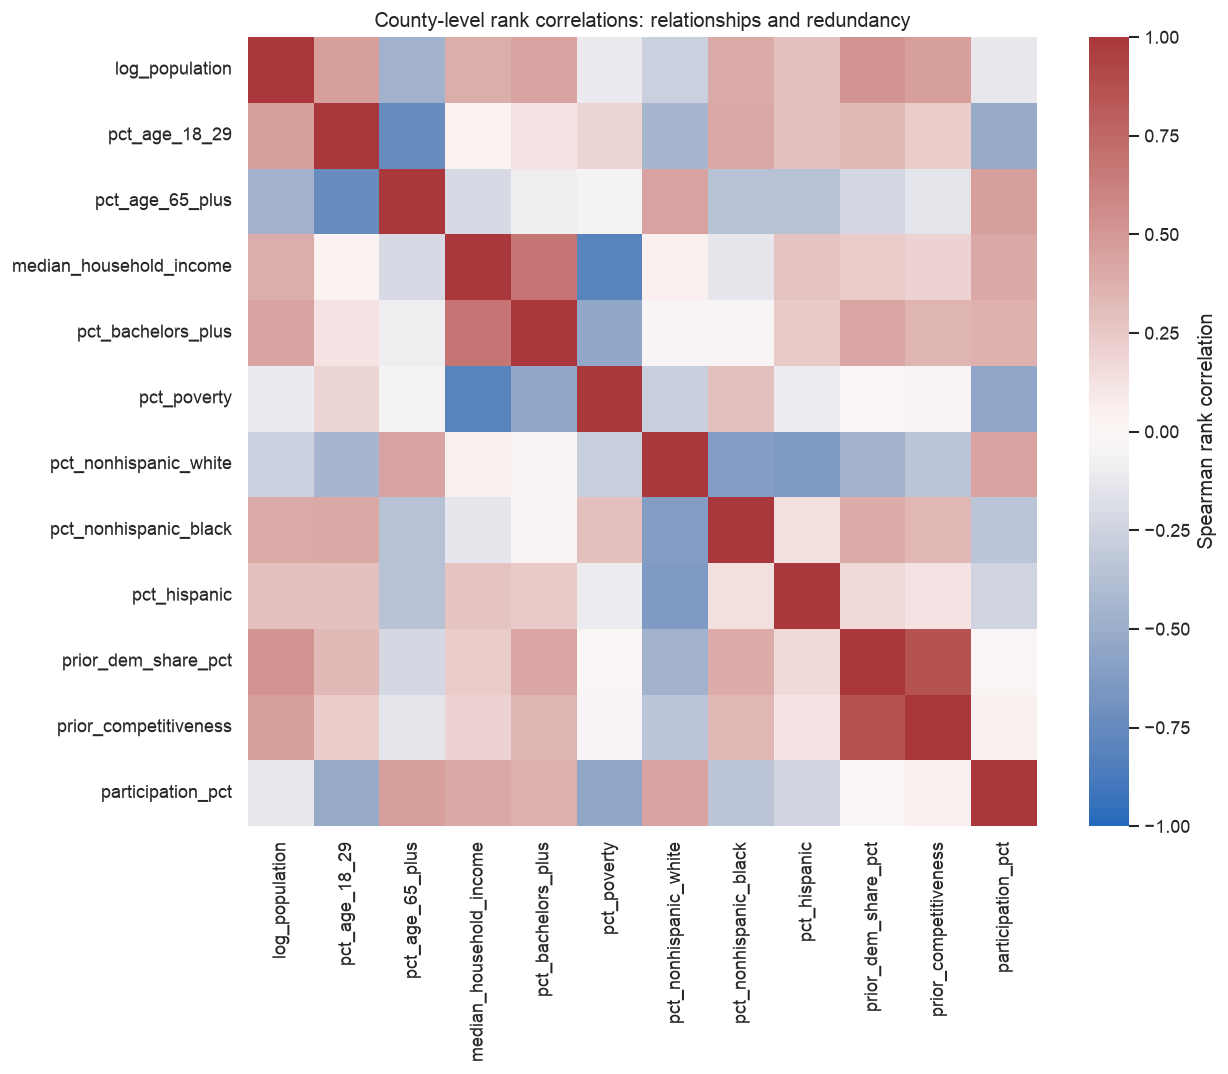

,Spearman correlation with participation
pct_poverty,-0.542
pct_age_18_29,-0.523
pct_age_65_plus,0.466
pct_nonhispanic_white,0.442
median_household_income,0.413
pct_bachelors_plus,0.371
pct_nonhispanic_black,-0.336
pct_hispanic,-0.244
log_population,-0.131
prior_competitiveness,0.048


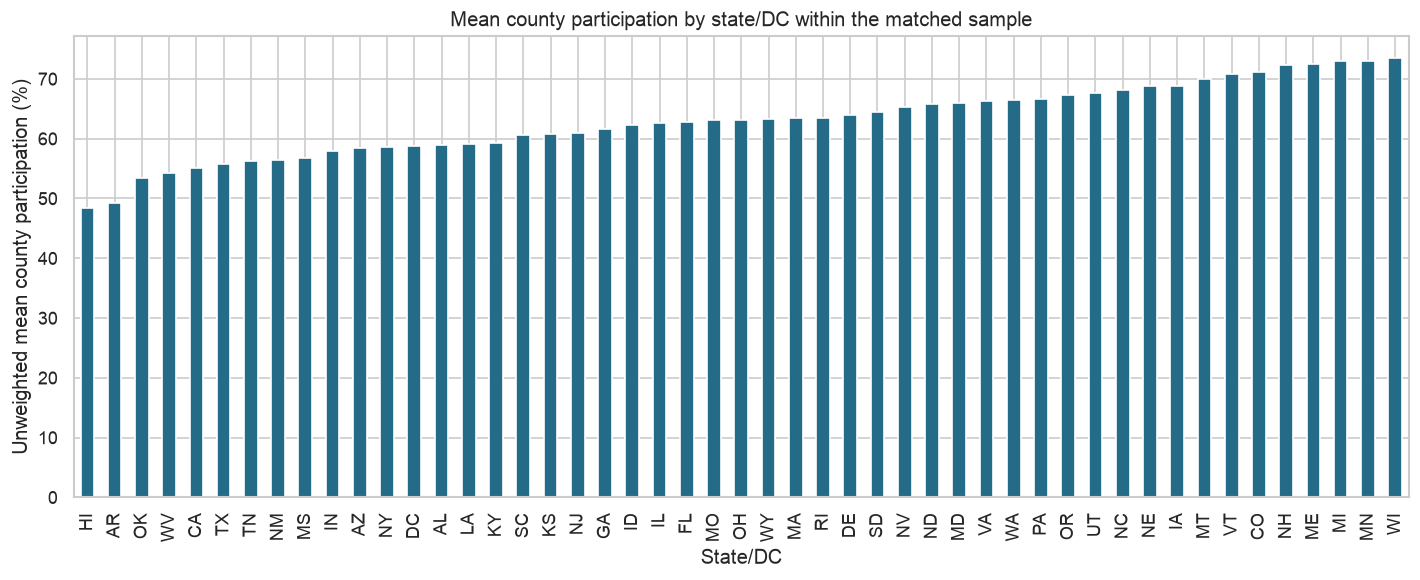

In [6]:
scatter_features = ['pct_bachelors_plus', 'median_household_income', 'pct_age_65_plus', 'prior_competitiveness']
scatter_labels = ['Adults 25+ with bachelor degree or higher (%)', 'Median household income (2024 dollars)', 'Residents age 65+ (%)', '2020 two-party competitiveness (0–100)']
figure, axes = plt.subplots(2, 2, figsize=(11, 8))
for axis, feature, label in zip(axes.flat, scatter_features, scatter_labels):
    sns.scatterplot(data=analysis, x=feature, y='participation_pct', ax=axis, s=11, alpha=0.35, color='#246b88', edgecolor=None)
    axis.set(xlabel=label, ylabel='2024 participation proxy (%)', title='County association; not a causal effect')
save_figure('03_feature_relationships.png')
correlations = analysis[FEATURES + ['participation_pct']].corr(method='spearman')
correlations.to_csv(REPORTS / 'spearman_correlations.csv')
figure, axis = plt.subplots(figsize=(11, 9))
sns.heatmap(correlations, cmap='vlag', center=0, vmin=-1, vmax=1, ax=axis, square=True, cbar_kws={'label': 'Spearman rank correlation'})
axis.set(title='County-level rank correlations: relationships and redundancy')
save_figure('04_correlations.png')
target_correlations = correlations['participation_pct'].drop('participation_pct').sort_values(key=lambda values: values.abs(), ascending=False)
display(target_correlations.rename('Spearman correlation with participation').to_frame().round(3))
state_summary = analysis.groupby('state').agg(counties=('county_fips', 'size'), mean_county_participation=('participation_pct', 'mean'), votes=('total_votes', 'sum'), adults=('adult_population', 'sum'))
state_summary['aggregate_participation'] = 100 * state_summary['votes'] / state_summary['adults']
state_summary.to_csv(REPORTS / 'state_summary.csv')
figure, axis = plt.subplots(figsize=(12, 5))
state_summary['mean_county_participation'].sort_values().plot.bar(ax=axis, color='#246b88')
axis.set(title='Mean county participation by state/DC within the matched sample', xlabel='State/DC', ylabel='Unweighted mean county participation (%)')
save_figure('05_state_patterns.png')

## 5. Baseline modeling and validation design
The outcome is continuous, so this is a regression task. **MAE in participation percentage points** is the primary metric: a 5-point MAE means predictions miss by 5 participation points per county on average. RMSE gives more weight to large errors; R² compares squared error with predicting the test-set mean and can be negative. All scores weight counties equally.

Use one fixed 80/20 split of state/DC groups, seed 42. No state appears in both training and test sets. This assesses geographic transfer to counties in unseen states, not future-election performance. Counties within a state are related; a random row split would be a weaker check. Five-fold GroupKFold on training states compares prespecified models. Select the model using training CV MAE only; report the held-out state test once. EDA uses the full sample descriptively, so this remains exploratory rather than a preregistered confirmatory study.

Models: a training-mean DummyRegressor; Ridge (alpha=10) with median imputation and scaling; RandomForestRegressor (200 trees, max_depth=12, min_samples_leaf=10) with median imputation. These settings are fixed for this initial analysis, with no extensive hyperparameter search. Imputation and scaling fit inside each training fold. The original vote counts, adult denominator, current-election vote shares, FIPS, and state codes are excluded from model inputs. Population size is retained as an explicitly defined demographic predictor; a sensitivity check removes it.

Training: **2,606 counties in 39 state/DC groups**. Test: **493 counties in 10 groups** (IN, MA, ME, NC, ND, NE, NV, VT, WA, WV). Training CV selects **Ridge regression**.

,model,cv_mae_mean_pp,cv_mae_sd_pp,test_mae_pp,test_rmse_pp,test_r2,predictions_outside_0_100
0,Training-mean baseline,8.339,0.744,7.788,9.497,-0.061,0
1,Ridge regression,4.833,0.243,5.576,6.868,0.445,0
2,Random forest,4.839,0.361,5.404,6.677,0.476,0


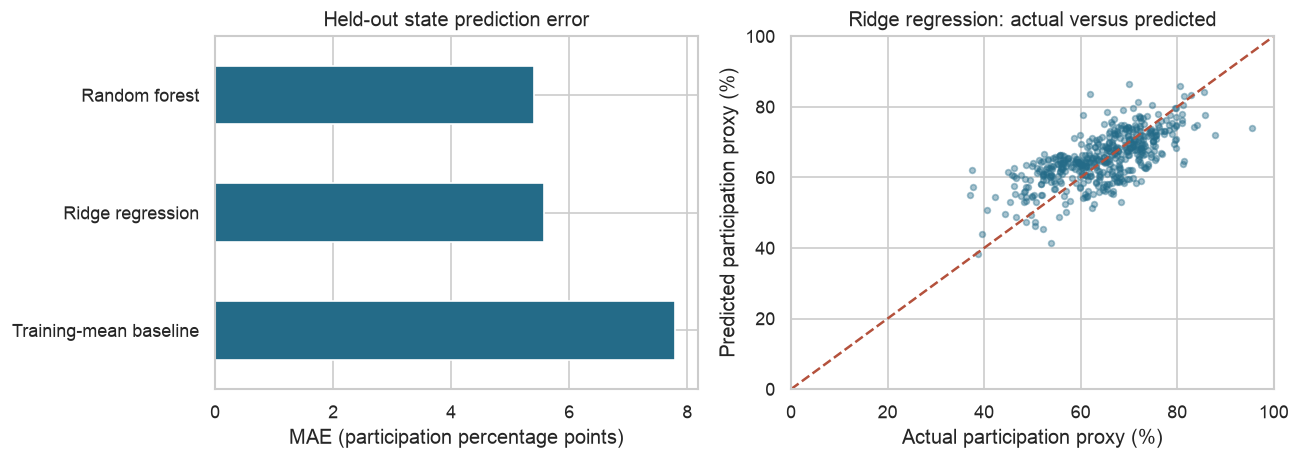

In [7]:
features = analysis[FEATURES]
outcome = analysis['participation_pct']
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_indices, test_indices = next(splitter.split(features, outcome, groups=analysis['state']))
train_features, test_features = features.iloc[train_indices], features.iloc[test_indices]
train_outcome, test_outcome = outcome.iloc[train_indices], outcome.iloc[test_indices]
train_groups = analysis.iloc[train_indices]['state']
test_groups = analysis.iloc[test_indices]['state']
assert set(train_groups).isdisjoint(set(test_groups))
analysis['split'] = 'train'
analysis.loc[analysis.index[test_indices], 'split'] = 'test'
analysis.to_csv(PROCESSED / 'county_analysis.csv', index=False)
models = {
    'Training-mean baseline': Pipeline([('impute', SimpleImputer(strategy='median')), ('model', DummyRegressor(strategy='mean'))]),
    'Ridge regression': Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('model', Ridge(alpha=10))]),
    'Random forest': Pipeline([('impute', SimpleImputer(strategy='median')), ('model', RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=10, random_state=SEED, n_jobs=1))]),
}
cv = GroupKFold(n_splits=5)
metric_rows = []
cv_fold_rows = []
fitted_models = {}
predictions = analysis.iloc[test_indices][['county_fips', 'state', 'county_name', 'participation_pct']].copy()
for model_name, estimator in models.items():
    cv_errors = -cross_val_score(estimator, train_features, train_outcome, groups=train_groups, cv=cv, scoring='neg_mean_absolute_error', n_jobs=1)
    for fold_number, error in enumerate(cv_errors, start=1):
        cv_fold_rows.append({'model': model_name, 'fold': fold_number, 'mae_pp': float(error)})
    fitted = clone(estimator).fit(train_features, train_outcome)
    predicted = fitted.predict(test_features)
    predictions[model_name] = predicted
    fitted_models[model_name] = fitted
    metric_rows.append({'model': model_name, 'cv_mae_mean_pp': cv_errors.mean(), 'cv_mae_sd_pp': cv_errors.std(ddof=1), 'test_mae_pp': mean_absolute_error(test_outcome, predicted), 'test_rmse_pp': np.sqrt(mean_squared_error(test_outcome, predicted)), 'test_r2': r2_score(test_outcome, predicted), 'predictions_outside_0_100': int(((predicted < 0) | (predicted > 100)).sum())})
metrics = pd.DataFrame(metric_rows)
best_name = metrics.sort_values('cv_mae_mean_pp').iloc[0]['model']
best_model = fitted_models[best_name]
metrics.to_csv(REPORTS / 'model_metrics.csv', index=False)
pd.DataFrame(cv_fold_rows).to_csv(REPORTS / 'cv_fold_metrics.csv', index=False)
predictions.to_csv(REPORTS / 'holdout_predictions.csv', index=False)
display(Markdown(f"Training: **{len(train_indices):,} counties in {train_groups.nunique()} state/DC groups**. Test: **{len(test_indices):,} counties in {test_groups.nunique()} groups** ({', '.join(sorted(test_groups.unique()))}). Training CV selects **{best_name}**."))
display(metrics.round(3))
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
metrics.set_index('model')['test_mae_pp'].plot.barh(ax=axes[0], color='#246b88')
axes[0].set(title='Held-out state prediction error', xlabel='MAE (participation percentage points)', ylabel='')
best_predictions = predictions[best_name].to_numpy()
axes[1].scatter(test_outcome, best_predictions, s=12, alpha=0.4, color='#246b88')
axes[1].plot([0, 100], [0, 100], linestyle='--', color='#b4513c')
axes[1].set(title=f'{best_name}: actual versus predicted', xlabel='Actual participation proxy (%)', ylabel='Predicted participation proxy (%)', xlim=(0, 100), ylim=(0, 100))
save_figure('06_model_performance.png')

## 6. Model interpretation, error checks, and sensitivity
Permutation importance measures the increase in held-out MAE after shuffling one predictor. It is model-specific predictive importance, not a causal effect or proof that changing the feature changes participation. Correlated features can share or mask importance; negative values mean the shuffle happened to improve predictions. The test set is used for descriptive interpretation after model selection, not to tune the model.

Two checks evaluate limits of the measured outcome. First, score the fixed model separately on counties with and without source candidate-total reconciliation flags; subgroup errors are descriptive, not a new validation experiment. Second, refit the same selected model family without population size and, separately, without race/ethnicity features. These are post-selection sensitivity analyses, not alternative models chosen on test performance. They cannot establish that proxy relationships or ecological bias are absent.

,feature,mae_increase_pp,repeat_sd_pp
4,pct_bachelors_plus,0.625,0.079
1,pct_age_18_29,0.580,0.130
0,log_population,0.558,0.122
6,pct_nonhispanic_white,0.481,0.090
7,pct_nonhispanic_black,0.446,0.036
3,median_household_income,0.406,0.076
2,pct_age_65_plus,0.394,0.073
10,prior_competitiveness,0.194,0.058
9,prior_dem_share_pct,0.165,0.050
5,pct_poverty,0.029,0.031


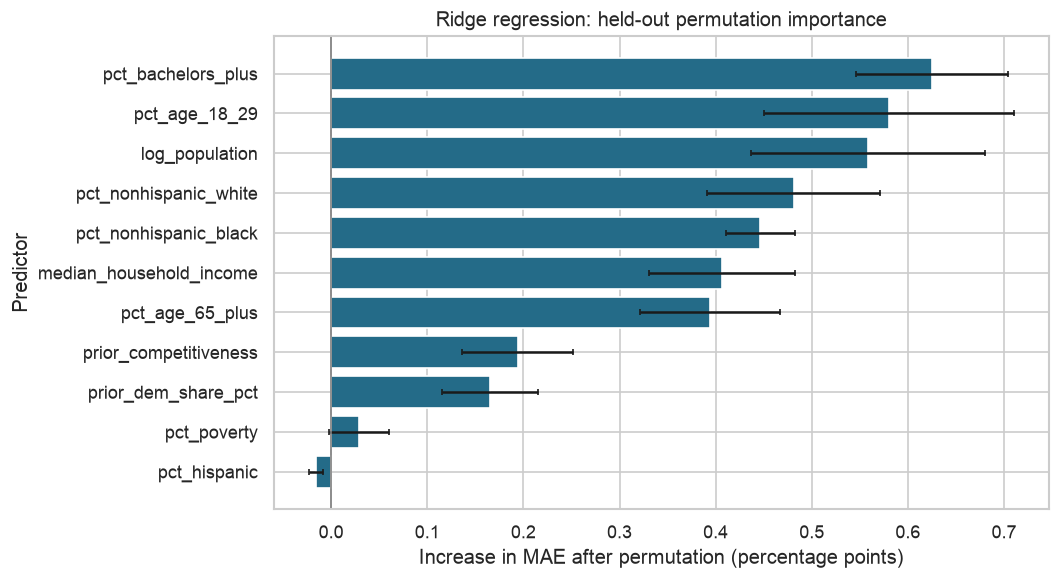

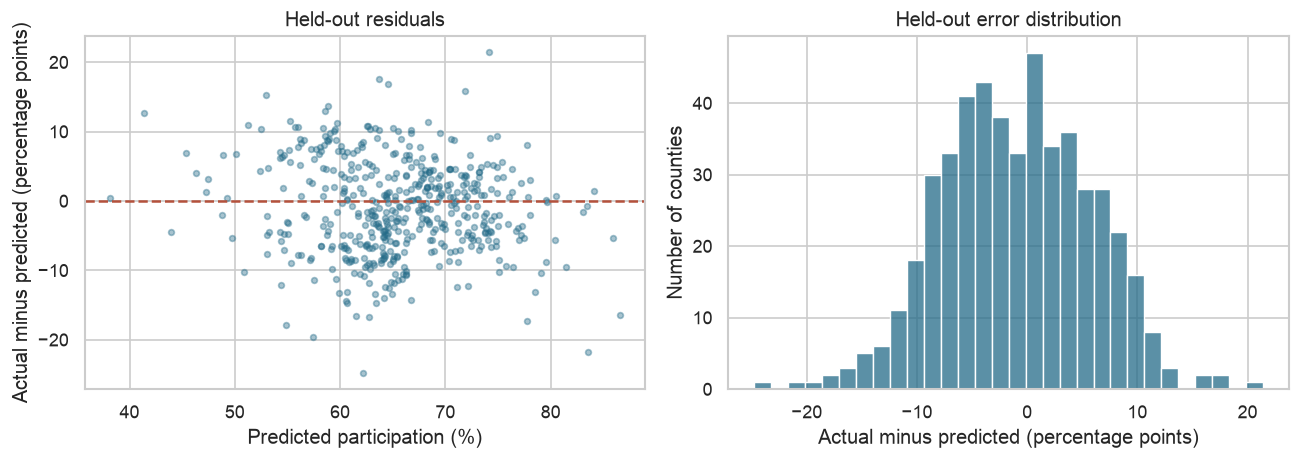

,analysis,test_counties,test_mae_pp
0,Without population size,493,5.540
1,Without race/ethnicity shares,493,4.945
2,Fixed-model score: reconciliation flag=False,479,5.628
3,Fixed-model score: reconciliation flag=True,14,3.818


,counties,mae_pp
state,,
WV,55,9.485
NC,100,6.642
MA,14,6.586
NV,17,6.394
IN,92,5.664
ND,53,4.588
NE,93,4.161
VT,14,3.818
WA,39,3.420


In [8]:
importance_result = permutation_importance(best_model, test_features, test_outcome, scoring='neg_mean_absolute_error', n_repeats=10, random_state=SEED, n_jobs=1)
importance = pd.DataFrame({'feature': FEATURES, 'mae_increase_pp': importance_result.importances_mean, 'repeat_sd_pp': importance_result.importances_std}).sort_values('mae_increase_pp', ascending=False)
importance.to_csv(REPORTS / 'permutation_importance.csv', index=False)
display(importance.round(3))
figure, axis = plt.subplots(figsize=(9, 5))
ordered_importance = importance.sort_values('mae_increase_pp')
axis.barh(ordered_importance['feature'], ordered_importance['mae_increase_pp'], xerr=ordered_importance['repeat_sd_pp'], color='#246b88', capsize=2)
axis.axvline(0, color='gray', linewidth=1)
axis.set(title=f'{best_name}: held-out permutation importance', xlabel='Increase in MAE after permutation (percentage points)', ylabel='Predictor')
save_figure('07_permutation_importance.png')
residuals = test_outcome.to_numpy() - best_predictions
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(best_predictions, residuals, s=12, alpha=0.4, color='#246b88')
axes[0].axhline(0, color='#b4513c', linestyle='--')
axes[0].set(title='Held-out residuals', xlabel='Predicted participation (%)', ylabel='Actual minus predicted (percentage points)')
sns.histplot(residuals, bins=30, ax=axes[1], color='#246b88')
axes[1].set(title='Held-out error distribution', xlabel='Actual minus predicted (percentage points)', ylabel='Number of counties')
save_figure('08_residual_diagnostics.png')
sensitivity_rows = []
for label, removed_features in {
    'Without population size': ['log_population'],
    'Without race/ethnicity shares': ['pct_nonhispanic_white', 'pct_nonhispanic_black', 'pct_hispanic'],
}.items():
    retained_features = [feature for feature in FEATURES if feature not in removed_features]
    fitted_sensitivity = clone(models[best_name]).fit(train_features[retained_features], train_outcome)
    sensitivity_predictions = fitted_sensitivity.predict(test_features[retained_features])
    sensitivity_rows.append({'analysis': label, 'test_counties': len(test_outcome), 'test_mae_pp': mean_absolute_error(test_outcome, sensitivity_predictions)})
for flagged in [False, True]:
    subgroup = analysis.iloc[test_indices]['total_reconciliation_flag'].to_numpy() == flagged
    if subgroup.any():
        sensitivity_rows.append({'analysis': f'Fixed-model score: reconciliation flag={flagged}', 'test_counties': int(subgroup.sum()), 'test_mae_pp': mean_absolute_error(test_outcome.to_numpy()[subgroup], best_predictions[subgroup])})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(REPORTS / 'sensitivity_checks.csv', index=False)
display(sensitivity.round(3))
state_errors = predictions.assign(absolute_error=np.abs(residuals)).groupby('state').agg(counties=('county_fips', 'size'), mae_pp=('absolute_error', 'mean'))
state_errors.to_csv(REPORTS / 'holdout_state_errors.csv')
display(state_errors.sort_values('mae_pp', ascending=False).round(3))

## 7. Findings and limitations
The next cell creates the executive findings directly from the executed analysis. These are observational county-level results within the matched sample. The README is generated from the same recorded values.

Principal limitations: a VAP proxy rather than official turnout; a five-year estimated population denominator; noncitizens/ineligible adults in that denominator; survey sampling error; potential differences between source county totals and candidate sums; unharmonized geography exclusions; unequal county sizes; one cross-sectional election; contemporaneous demographics; a single held-out state split; correlated predictors; and no causal identification. No campaign-spending or direct canvassing variable has been analyzed. Grouped validation reduces state overlap but does not make counties or states independent causal experiments.

In [9]:
selected_metrics = metrics.set_index('model').loc[best_name]
baseline_metrics = metrics.set_index('model').loc['Training-mean baseline']
improvement_pct = 100 * (baseline_metrics['test_mae_pp'] - selected_metrics['test_mae_pp']) / baseline_metrics['test_mae_pp']
top_correlations = [{'feature': str(feature), 'spearman': float(value)} for feature, value in target_correlations.head(4).items()]
top_importance = importance.head(4).to_dict(orient='records')
summary = {
    'audit': audit,
    'distribution': {key: float(value) for key, value in distribution.items()},
    'aggregate_participation_pct': float(weighted_participation),
    'target_iqr_outliers': int(analysis['target_iqr_outlier'].sum()),
    'train_counties': len(train_indices), 'test_counties': len(test_indices),
    'train_states': sorted(train_groups.unique()), 'test_states': sorted(test_groups.unique()),
    'selected_model': best_name,
    'model_metrics': metrics.to_dict(orient='records'),
    'mae_improvement_over_dummy_pct': float(improvement_pct),
    'top_correlations': top_correlations,
    'top_importance': top_importance,
    'sensitivity': sensitivity.to_dict(orient='records'),
    'nonmissing_predictor_cells': int(analysis[FEATURES].notna().sum().sum()),
    'missing_predictor_cells': int(analysis[FEATURES].isna().sum().sum()),
    'features': FEATURES,
}
(REPORTS / 'analysis_summary.json').write_text(json.dumps(summary, indent=2) + '\n')
(REPORTS / 'cleaning_audit.json').write_text(json.dumps(audit, indent=2) + '\n')
findings = f'''### Executed findings
- The final sample contains **{len(analysis):,} counties/county equivalents** in **{analysis['state'].nunique()} states/DC groups**.
- Mean county participation is **{target.mean():.2f}%**, median **{target.median():.2f}%**, with an aggregate sample ratio of **{weighted_participation:.2f}%**.
- Training CV selects **{best_name}**. Its held-out state MAE is **{selected_metrics['test_mae_pp']:.2f} percentage points**, compared with **{baseline_metrics['test_mae_pp']:.2f}** for the training-mean baseline ({improvement_pct:.1f}% lower MAE).
- The selected model's held-out RMSE is **{selected_metrics['test_rmse_pp']:.2f} points** and R² is **{selected_metrics['test_r2']:.3f}**.
- The leading permutation features in this fitted model are **{', '.join(importance.head(3)['feature'])}**. These rankings describe predictive reliance and do not establish causation.
- FEC spending, prior turnout, urban/rural classification, and county clustering remain future work.
- Ridge and random forest have nearly identical training CV MAE in this run; the tiny difference is much smaller than fold-to-fold variation. Random forest has a slightly lower held-out MAE, but the selection rule remains training CV rather than the test ranking.
- Removing race/ethnicity shares improves the selected model's held-out MAE in this post-selection sensitivity check. This is a reason to revisit feature stability using training-only validation in future work, not to choose a replacement model on the same test set.
'''
display(Markdown(findings))

### Executed findings
- The final sample contains **3,099 counties/county equivalents** in **49 states/DC groups**.
- Mean county participation is **62.50%**, median **62.78%**, with an aggregate sample ratio of **59.31%**.
- Training CV selects **Ridge regression**. Its held-out state MAE is **5.58 percentage points**, compared with **7.79** for the training-mean baseline (28.4% lower MAE).
- The selected model's held-out RMSE is **6.87 points** and R² is **0.445**.
- The leading permutation features in this fitted model are **pct_bachelors_plus, pct_age_18_29, log_population**. These rankings describe predictive reliance and do not establish causation.
- FEC spending, prior turnout, urban/rural classification, and county clustering remain future work.
- Ridge and random forest have nearly identical training CV MAE in this run; the tiny difference is much smaller than fold-to-fold variation. Random forest has a slightly lower held-out MAE, but the selection rule remains training CV rather than the test ranking.
- Removing race/ethnicity shares improves the selected model's held-out MAE in this post-selection sensitivity check. This is a reason to revisit feature stability using training-only validation in future work, not to choose a replacement model on the same test set.


## 8. Next steps and reproducibility
1. Audit excluded geographies and source vote discrepancies; obtain a directly downloaded MEDSL source copy when possible.
2. Compare the proxy with a validated election-year voting-eligible or registered-voter turnout measure. Quantify how ACS uncertainty and denominator definitions affect findings.
3. Add prior turnout only after matching each election to an appropriate population/eligibility denominator. Add an explicit urban/rural classification if useful.
4. Add FEC measures only after defining the financial concept and a defensible geographic allocation. Campaign expenditures are not automatically county-level exposure.
5. Extend to multiple elections using demographic releases actually available before each election, and evaluate chronologically before claiming forecasting ability.
6. Consider clustering later as a descriptive extension, with a stated purpose, scaled inputs, cluster validation, and understandable profile labels.
7. Review data limitations and findings in plain language. This notebook supports aggregate understanding; it does not justify individual-level claims or causal claims about engagement interventions.

Run all cells from a fresh kernel using the local raw snapshots. Expected dependencies and exact versions are in `requirements.txt`; checksums and source locations are in `data/raw/sources.json`. Intermediate audit tables, plots, test predictions, fold scores, and final metrics are saved under `reports/`. No classroom submission or repository publication is performed by this notebook.